# **На основе предпроектного опроса выдвиули несколько гипотез**


Подготовка данных:

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize']=(8,5)
df=pd.read_excel('/Опрос1.xlsx')
q2 =[c for c in df.columns if 'участвовали в кейс' in c][0]
df= df[df[q2]!='Нет, не интересуюсь этим'].copy()
df.rename(columns={
    q2: 'Опыт',
    [c for c in df.columns if 'сложное' in c][0]: 'Сложности',
    [c for c in df.columns if 'уходит' in c][0]: 'Время',
    [c for c in df.columns if 'нейросети' in c][0]: 'Нейросети',
    [c for c in df.columns if 'изменить в своей' in c][0]: 'Запрос'
},inplace=True)

**гипотеза 1** :Школьники, которые еще не участвовали в чемпионатах, чаще выбирают «Придумать идею» как главную сложность, чем те, кто уже участвовал

Процент тех, кому сложно придумать идею:
Идея                          False  True 
Опыт                                      
Да, участвовал(а)              30.8   69.2
Нет, но хотел бы попробовать   15.4   84.6


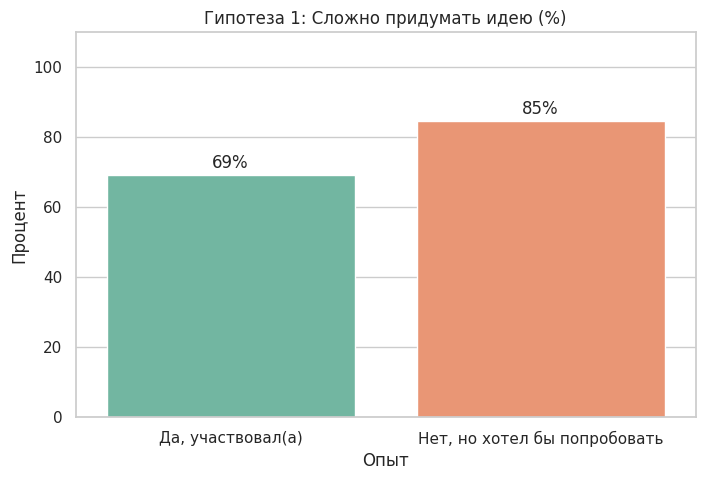

In [17]:
df['Идея']=df['Сложности'].str.contains('Придумать идею', na=False)
h1=pd.crosstab(df['Опыт'],df['Идея'],normalize='index') * 100
print("Процент тех, кому сложно придумать идею:")
print(h1.round(1))
plt.figure()
ax1=sns.barplot(x=h1.index,y=h1[True],hue=h1.index,legend=False,palette='Set2')
for i, val in enumerate(h1[True]):
    plt.text(i, val + 2, f'{val:.0f}%',ha='center')
plt.title('Гипотеза 1: Сложно придумать идею (%)')
plt.ylabel('Процент')
plt.ylim(0,110)
plt.show()

**гипотеза 2**:Школьники, которые использует ChatGPT при решении кейсов, решают их быстрее тех, кто не пользуется ChatGPT

Всего людей в анализе: 25
Процент тех, кто решает за час и меньше:


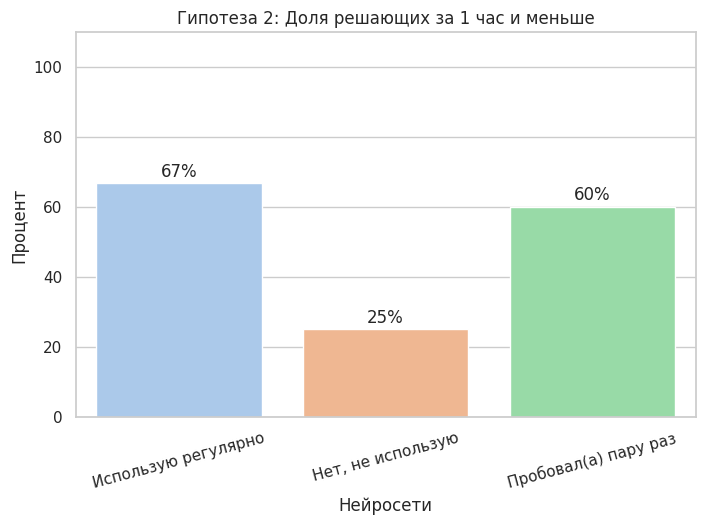

In [18]:
df2=df[df['Нейросети']!='Не знал(а), что так можно'].copy()
df2['Быстро'] = df2['Время'].isin(['Меньше 30 минут', '30–60 минут'])
h2=pd.crosstab(df2['Нейросети'],df2['Быстро'],normalize='index') * 100
print(f"Всего людей в анализе: {len(df2)}")
print("Процент тех, кто решает за час и меньше:")
plt.figure()
ax2=sns.barplot(x=h2.index,y=h2[True],hue=h2.index,legend=False,palette='pastel')
for i, val in enumerate(h2[True]):
    plt.text(i,val+ 2,f'{val:.0f}%',ha='center')
plt.title('Гипотеза 2: Доля решающих за 1 час и меньше')
plt.ylabel('Процент')
plt.xticks(rotation =15)
plt.ylim(0,  110)
plt.show()

**гипотеза 3**: Многим школьникам не хватает практики при решении кейсов

Что бы вы хотели изменить в подготовке:
Запрос
Решать больше кейсов                     53.8
Получать быстрый ответ на моё решение    30.8
Научиться работать в команде             15.4
Name: proportion, dtype: float64


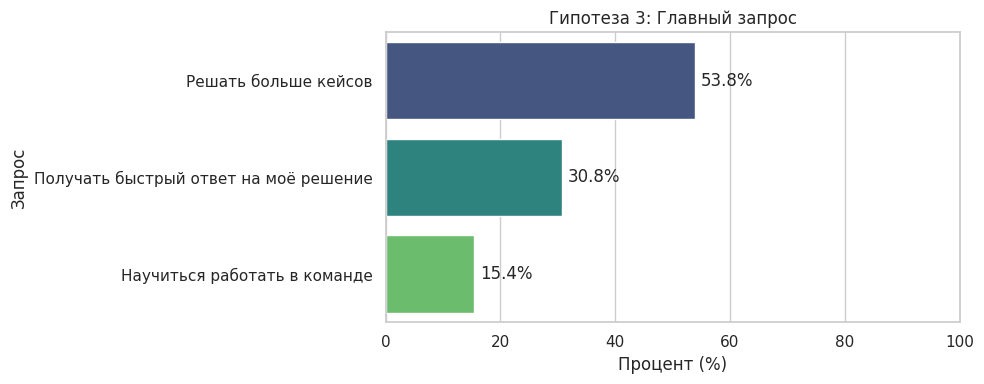

In [19]:
h3=df['Запрос'].value_counts(normalize=True) * 100
print("Что бы вы хотели изменить в подготовке:")
print(h3.round(1))
plt.figure(figsize=(10, 4))
ax3=sns.barplot(x=h3.values,y=h3.index,hue=h3.index,legend=False,palette='viridis')
for i,val in enumerate(h3.values):
    plt.text(val+1,i,f'{val:.1f}%' , va='center')
plt.title('Гипотеза 3: Главный запрос')
plt.xlabel('Процент (%)')
plt.xlim(0,100)
plt.tight_layout()
plt.show()

**Выводы**

1.85% новичков (кто еще не участвовал) и 69% опытных школников указали, что им сложно придумать идею.Это подтверждает гипотезу.В нашем продукте школьники смогут просматривать эталонное решение каждого кейса, это поможет им получить опыт в решении кейсов и облегчит в будущем решение кейсов.

2.Среди тех, кто регулярно использует нейросети, 67% решают кейс за час и меньше. Среди тех, кто не использует ИИ, таких только 25%.Разница почти в 2,5 раза доказывает, что ИИ реально помогает быстрее справляться с задачами. В наше приложение даёт структуру: в одном месте можно и проверить решение кейса, и найти новый кейс, и посмтретьполезную информацию на карточках. Школьники уже активно используют нейросети, а значит наше приложение будет для них понятным и полезным.

3.Больше половины (53,8%) хотят «Решать больше кейсов», а на втором месте (30,8%) — «Получать быстрый ответ на решение». Мы создаем тренажер с базой кейсов и моментальной ИИ-проверкой. Это закрывает 84,6% (53,8%+30,8%) всех запросов аудитории.